# Cornell tennis interviews: source audit and EDA

Executed locally, October 15, 2026. Source: [ConvoKit tennis](https://convokit.cornell.edu/documentation/tennis.html)
and [the original Cornell release](https://www.cs.cornell.edu/~liye/tennis.html).
We inspect the actual legacy native JSON, without installing ConvoKit/SpaCy or extracting parsed annotations.
No learner training runs here. No raw transcripts are published in notebook outputs.

Reproduce from the repository root: `python3 -m research.scripts.tennis.fetch`, then `audit`, `prototypes`, `additional`, `diagnostics`.
These scripts keep raw data and full candidate CSVs in the external `tennis-research-cache` folder.
The current setup needs existing numpy/pandas/sklearn/matplotlib/openpyxl/IPython/psutil.


In [1]:
import json
from pathlib import Path
import sys
project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "research/scripts/tennis").is_dir())
if str(project) not in sys.path: sys.path.insert(0, str(project))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from research.scripts.tennis.common import OUT, PRIVATE
audit = json.loads((OUT / "cornell_audit.json").read_text())
joins = json.loads((OUT / "join_summary.json").read_text())
extra = json.loads((OUT / "additional_audit.json").read_text())
meta = pd.read_csv(OUT / "cornell_interview_metadata.csv")


In [2]:
display(pd.DataFrame({"Count": {"Players":audit["players"],"Users including REPORTER":audit["speakers_including_reporter"],
    "Utterances":audit["utterances"],"Question-answer conversations":audit["qa_conversations"],"Interview records":audit["interviews"],
    "Accepted distinct sporting matches":joins["unique_interview_source_matches"]}}))
display(pd.DataFrame({"Interviews":audit["gender_interviews"],"Players":audit["gender_players"]}))
print("Legacy keys: user / root / reply-to / timestamp; interview key = conversations[root]['match_id'].")
print("Date mismatches:",audit["original_vs_utterance_date_mismatches"],"Answer reconstruction mismatches:",audit["answer_reconstruction_mismatches"])


,Count
Players,358
Users including REPORTER,359
Utterances,163948
Question-answer conversations,81974
Interview records,6467
Accepted distinct sporting matches,5031


,Interviews,Players
M,3633,191
F,2834,167


Legacy keys: user / root / reply-to / timestamp; interview key = conversations[root]['match_id'].
Date mismatches: 0 Answer reconstruction mismatches: 0


`match_id` in this source identifies an interview, not a unique sporting match.
Zero reconstruction/date mismatches verify conversion consistency, not transcript-to-match truth or original online availability.


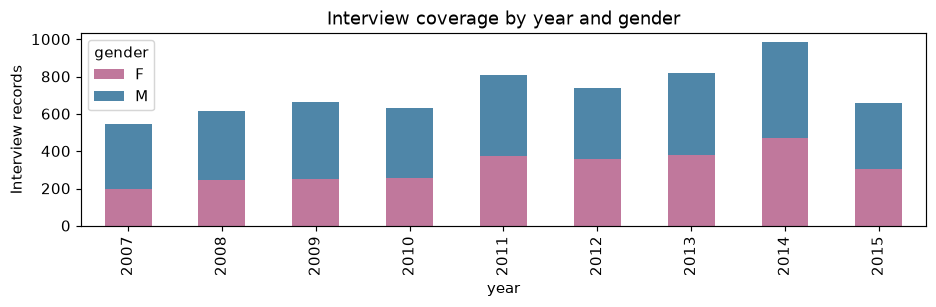

In [3]:
yearly=meta.groupby(["year","gender"]).size().unstack()
yearly.plot.bar(stacked=True,figsize=(9,3),color=["#c0789c","#4f86a8"])
plt.ylabel("Interview records");plt.title("Interview coverage by year and gender");plt.tight_layout();plt.show()


**Insight:** Both genders span all nine years, but coverage is uneven. Counts measure interviews, not all matches played or equally sampled players.
Separate men's/women's summaries are essential before interpreting pooled prediction performance.


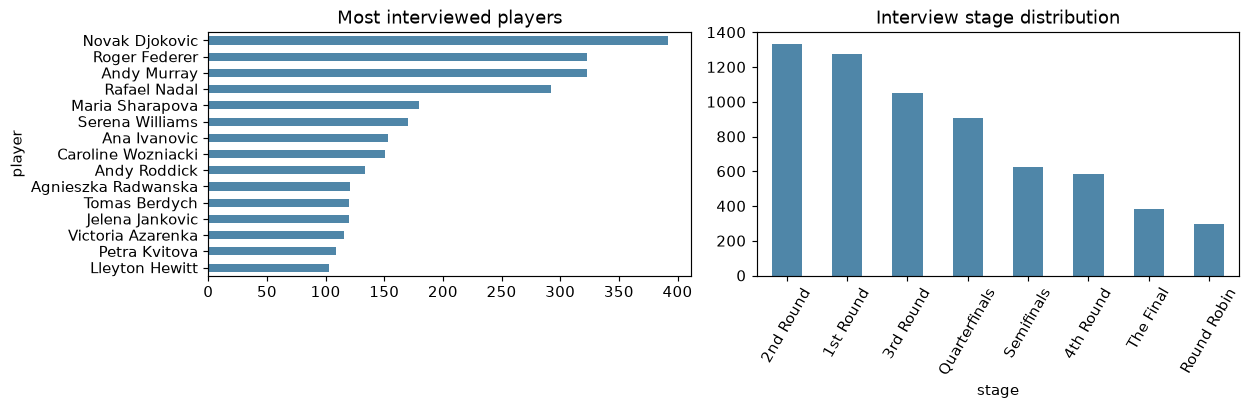

Top-ten player share: 34.6 %
Grand Slam share: 43.6 %
Winning-player source interview share: 68.0 %


In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
meta.player.value_counts().head(15).sort_values().plot.barh(ax=axes[0],color="#4f86a8")
meta.stage.value_counts().plot.bar(ax=axes[1],color="#4f86a8",rot=60)
axes[0].set_title("Most interviewed players");axes[1].set_title("Interview stage distribution")
plt.tight_layout();plt.show()
print("Top-ten player share:",round(extra["corpus_top10_player_interview_share"]*100,1),"%")
print("Grand Slam share:",round(extra["corpus_grandslam_interview_share"]*100,1),"%")
print("Winning-player source interview share:",round(extra["corpus_source_winner_interview_share"]*100,1),"%")


**Insight:** Stars account for a substantial share of source documents and 68% of interviews follow wins.
The final A/B label can still be balanced because its orientation is independent of the winner.
Interview selection bias and target class balance are different questions.


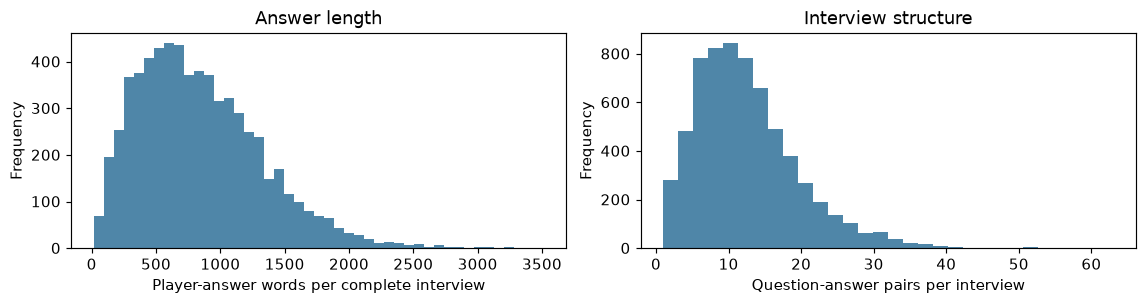

,measure,count
0,Answers ≤5 words,7810
1,Exact narrow boilerplate,1749
2,Empty answers,0
3,Duplicate full answer documents,0
4,Repeated long sections (≥30 words),0


In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,3))
meta.answer_words.plot.hist(bins=45,ax=axes[0],color="#4f86a8")
meta.qa_pairs.plot.hist(bins=30,ax=axes[1],color="#4f86a8")
axes[0].set(xlabel="Player-answer words per complete interview",title="Answer length")
axes[1].set(xlabel="Question-answer pairs per interview",title="Interview structure")
plt.tight_layout();plt.show()
display(pd.DataFrame([{"measure":"Answers ≤5 words","count":audit["answers_at_most_5_words"]},
    {"measure":"Exact narrow boilerplate","count":audit["exact_boilerplate_answers"]},
    {"measure":"Empty answers","count":audit["empty_answers"]},
    {"measure":"Duplicate full answer documents","count":audit["duplicate_full_answer_interviews"]},
    {"measure":"Repeated long sections (≥30 words)","count":audit["duplicate_long_answer_sections_beyond_first"]}]))


**Insight:** Median full answers total 769 words; most exceed 512 words, which is not the same as the E5 token limit.
A fixed passage policy is necessary. Many short answers need their question context; removing every short answer could remove useful evidence.
Exact-duplicate checks do not establish absence of near-duplicates.


In [6]:
reviews=pd.read_csv(OUT/"manual_content_review.csv")
sample=pd.read_csv(OUT/"manual_review_sample.csv")
reviewed=sample.merge(reviews,on="interview_id",validate="one_to_one")
display(reviewed[["interview_id","player","date","gender","result","specific_context_0_to_2","review_note"]])
display(reviews.specific_context_0_to_2.value_counts().rename_axis("Subjective specificity").to_frame("Reviewed interviews"))
print("Full raw answers remain private at:",PRIVATE/"manual_review_texts.json")
print("Automated lexical flags are NOT human labels:",audit["keyword_flags_NOT_human_labels"])


,interview_id,player,date,gender,result,specific_context_0_to_2,review_note
0,854,Francesca Schiavone,2007-08-23,F,0,2,Ankle pain and retirement decision; concrete s...
1,718,Nicole Vaidisova,2007-01-19,F,1,2,Serving and crucial points alongside heat and ...
2,885,Paul-Henri Mathieu,2007-08-09,M,0,2,High-bouncing opponent shots and physical dete...
3,1195,Novak Djokovic,2007-06-26,M,1,2,Unexpectedly slow grass and changed court cond...
4,1749,Agnieszka Radwanska,2008-07-01,F,0,2,Opponent serve dominance and limited opportuni...
5,1499,Aleksandra Wozniak,2008-07-30,F,1,2,Discusses a loss although source labels a win;...
6,1380,Richard Gasquet,2008-04-24,M,0,2,Back pain; poor preparation; heavy legs and re...
7,1617,Kei Nishikori,2008-06-11,M,1,1,Grass movement adjustment but many answers req...
8,2411,Francesca Schiavone,2009-06-30,F,0,1,Large-court experience and pressure; breakpoin...
9,2209,Svetlana Kuznetsova,2009-10-30,F,1,1,Explains incentives in a dead-rubber match and...


,Reviewed interviews
Subjective specificity,
2,22
1,9
0,5


Full raw answers remain private at: /Users/dimabshara/Desktop/NLP/tennis-research-cache/derived/manual_review_texts.json
Automated lexical flags are NOT human labels: {'tactics': 0.6564094634297201, 'serve_return': 0.7222823565795577, 'condition': 0.5011597340343281, 'mentality': 0.7788773774547704, 'surface': 0.4360599969073759}


**Insight:** The 36 reviewed answer sets cover every year/gender/outcome stratum but are restricted to 70–350 words.
Human review found 22 detailed, 9 somewhat contextual and 5 generic/off-topic examples. This is not a population-prevalence estimate.
Interview 1499 explicitly describes a loss despite a source win label; it is excluded from construction.


In [7]:
linked=pd.read_csv(OUT/"cornell_match_join_audit.csv")
display(linked.join_status.value_counts().to_frame("Interviews"))
display(linked[linked.join_status!="matched"].head(12))
display(pd.read_json(OUT/"publisher_spot_checks.json"))
print("Original interview date range:",audit["date_min"],"to",audit["date_max"])
print("Missing original dates:",audit["missing_dates"],"Unknown opponents:",audit["missing_opponent"])


,Interviews
join_status,
matched,6366
unmatched,95
outcome_conflict_excluded,5
manual_transcript_conflict_excluded,1


,interview_id,player,gender,date,opponent,source_stage,source_tournament,candidate_count,join_status,match_id,player_key,target_tournament,outcome_agrees,source_match_file,source_match_row
15,15,Rafael Nadal,M,2015-06-16,Alexandr Dolgopolov,1st Round,AEGON CHAMPIONSHIPS,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN
22,22,Karolina Pliskova,F,2015-06-21,Angelique Kerber,The Final,AEGON CLASSIC BIRMINGHAM,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN
23,23,Angelique Kerber,F,2015-06-21,Karolina Pliskova,The Final,AEGON CLASSIC BIRMINGHAM,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN
28,28,Johanna Konta,F,2015-06-18,Karolina Pliskova,2nd Round,AEGON CLASSIC BIRMINGHAM,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN
57,57,Karolina Pliskova,F,2015-01-16,Petra Kvitova,The Final,APIA INTERNATIONAL SYDNEY,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN
59,59,Petra Kvitova,F,2015-01-16,Karolina Pliskova,The Final,APIA INTERNATIONAL SYDNEY,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN
106,106,Jack Sock,M,2015-03-17,Roberto Bautista Agut,3rd Round,BNP PARIBAS OPEN,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN
110,110,Simona Halep,F,2015-03-17,Karolina Pliskova,4th Round,BNP PARIBAS OPEN,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN
229,229,Lesia Tsurenko,F,2015-08-27,Karolina Pliskova,Quarterfinals,CONNECTICUT OPEN,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN
299,299,Karolina Pliskova,F,2015-02-21,Simona Halep,The Final,DUBAI DUTY FREE TENNIS CHAMPIONSHIPS,0,unmatched,NaN,NaN,NaN,NaN,NaN,NaN


,interview_id,publisher_url,player,date,first_answer_prefix_matches_publisher,historical_publish_timestamp_verified,note
0,0,https://www.asapsports.com/show_interview.php?...,Andy Murray,2015-06-21,False,False,Same-day semifinal is a deliberate negative co...
1,0,https://www.asapsports.com/show_interview.php?...,Andy Murray,2015-06-21,True,False,Dated publisher-content corroboration; not a h...
2,497,https://www.asapsports.com/show_interview.php?...,Andy Murray,2015-08-22,True,False,Dated publisher-content corroboration; not a h...


Original interview date range: 2007-01-15 to 2015-10-18
Missing original dates: 0 Unknown opponents: 940


**Insight:** 6,366/6,467 records have accepted deterministic links, but 98.44% link coverage is not independently measured accuracy.
The source originally used Tennis-Data too. Two publisher-content checks corroborate dated transcripts; the same-day wrong semifinal is rejected.
No first-publication times or open transcript redistribution license were established.

**Gate decision:** genuine language and thousands of provisional calendar candidates justify a focused source-rights/timing check.
A is not yet cleared for training as a strict historical-availability task. See `tennis_cornell_eda.md` and notebook 04.
